# LR stacking with nonlinear feature representations

This model retains Logistic Regression at both levels:
- Linear LR for additive effects.
- Spline LR for smooth nonlinear effects.
- Interaction LR for pairwise numeric relationships.
- Kernel LR for nonlinear patterns.
- A final LR combining their cross-fitted probabilities.

The aim is to improve on the strong plain LR result. No higher accuracy is guaranteed. The new model is **lr_stacking**; the components and equal averaging are descriptive comparisons.

Written but not executed or tested by the assistant. No GPU is required.


## 1. Locate the project

Use the original modeling environment. Colab mounts Drive only when you run this cell. Edit PROJECT_ROOT if necessary.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = None
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')
    PROJECT_ROOT = PROJECT_ROOT or '/content/drive/MyDrive/ADNI_capstone'

ROOT = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/scripts/lr_stacking.py').is_file()), None)
if ROOT is None or not (ROOT / 'src/scripts/lr_stacking.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the updated project folder.')
print(ROOT)


/Volumes/ColdCache/untitled folder/dddd/Tables_19Sep2026


## 2. Dependencies, only if needed

Skip the installation cell when the original modeling packages are already installed. No deep-learning package is required.


In [2]:
requirements_file = str(ROOT / 'requirements-modeling.txt')
%pip install -r "{requirements_file}"



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Fix the settings

Use the original five outer folds. Within each outer training set:
1. Use three inner folds to choose the combiner's regularization from three C values.
2. Inside each inner training subset, cross-fit the entire base pipelines again to train the combiner.
3. Select by inner accuracy at threshold 0.5, with log loss as tie-breaker.
4. Refit the chosen whole stack on the outer training data, then predict the outer held-out participants.

Plain LR gets its own three-value C search using the same selection rule. All transformations are fitted inside the relevant pipeline/split. No precomputed global spline/kernel/stacking features are used.

The four base C values and representation settings are fixed. Seed 42 is fixed, including random Fourier features. This is an exploratory follow-up on previously inspected data.


In [3]:
import json
import pandas as pd
from IPython.display import display, Markdown, Image
sys.path.insert(0, str(ROOT / 'src/scripts'))
from lr_stacking import load_cohorts, run_lr_stacking

cfg = json.loads((ROOT / 'config/lr_stacking.json').read_text())
REPORT = ROOT / 'reports/modeling' / cfg['run_name']
manifest, cohorts = load_cohorts(cfg)
display(pd.DataFrame([
    {'experiment': name, 'participants': len(frame), 'converters': int(frame.label.sum()),
     'nonconverters': int((frame.label == 0).sum())}
    for name, frame in cohorts.items()
]))
print(json.dumps(cfg, indent=2))


,experiment,participants,converters,nonconverters
0,clinical_reference,589,216,373
1,matched_clinical,222,118,104
2,matched_fusion,222,118,104


{
  "baseline_run": "artifacts/modeling/complete_cases",
  "run_name": "lr_stacking_v1",
  "experiments": [
    "clinical_reference",
    "matched_clinical",
    "matched_fusion"
  ],
  "seed": 42,
  "inner_folds": 3,
  "stacking_folds": 3,
  "threshold": 0.5,
  "bootstrap_repetitions": 1000,
  "max_iter": 10000,
  "meta_C_candidates": [
    0.1,
    1.0,
    10.0
  ],
  "baseline_C_candidates": [
    0.1,
    1.0,
    10.0
  ],
  "view_C": {
    "linear": 0.1,
    "spline": 0.1,
    "interactions": 0.03,
    "rbf": 0.1
  },
  "spline_knots": 4,
  "spline_degree": 2,
  "rbf_components": 128,
  "rbf_gamma": 0.05
}


## 4. Fit and evaluate

This is the cell that starts fitting. Nested stacking needs many more LR fits than the original baseline. It runs on CPU and prints each outer fold.

Existing output folders are protected from overwrite. Skip this cell to inspect a completed run. Change run_name for an intentional new experiment.


In [4]:
results = run_lr_stacking(cfg)


LR stacking: clinical_reference, outer fold 1/5
LR stacking: clinical_reference, outer fold 2/5
LR stacking: clinical_reference, outer fold 3/5
LR stacking: clinical_reference, outer fold 4/5
LR stacking: clinical_reference, outer fold 5/5
LR stacking: matched_clinical, outer fold 1/5
LR stacking: matched_clinical, outer fold 2/5
LR stacking: matched_clinical, outer fold 3/5
LR stacking: matched_clinical, outer fold 4/5
LR stacking: matched_clinical, outer fold 5/5
LR stacking: matched_fusion, outer fold 1/5
LR stacking: matched_fusion, outer fold 2/5
LR stacking: matched_fusion, outer fold 3/5
LR stacking: matched_fusion, outer fold 4/5
LR stacking: matched_fusion, outer fold 5/5
Finished: reports/modeling/lr_stacking_v1


## 5. All model metrics

Compare models within each cohort. The broader clinical cohort is different from the matched cohort. AUROC and AP are higher-is-better; Brier is lower-is-better. Accuracy is evaluated at the fixed 0.5 threshold.

The tuned LR reference in this run uses accuracy-based inner selection and can differ from tuned LR in the prior hybrid run, which selected by log loss.


,experiment,model,participants,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,auroc,average_precision,brier_score
0,clinical_reference,logistic_regression,589,84.4%,81.0%,75.0%,89.8%,77.9%,82.4%,0.912,0.852,0.110
1,clinical_reference,tuned_logistic_regression,589,85.1%,81.7%,76.4%,90.1%,78.9%,83.2%,0.912,0.850,0.111
2,clinical_reference,lr_stacking,589,83.7%,81.6%,71.8%,90.6%,76.4%,81.2%,0.907,0.861,0.114
3,clinical_reference,lr_linear_view,589,85.1%,82.3%,75.5%,90.6%,78.7%,83.0%,0.912,0.852,0.111
4,clinical_reference,lr_spline_view,589,83.2%,79.4%,73.1%,89.0%,76.1%,81.1%,0.912,0.861,0.113
5,clinical_reference,lr_interactions_view,589,82.2%,80.7%,67.6%,90.6%,73.6%,79.1%,0.889,0.817,0.127
6,clinical_reference,lr_rbf_view,589,82.5%,78.1%,72.7%,88.2%,75.3%,80.4%,0.880,0.826,0.133
7,clinical_reference,lr_equal_voting,589,84.0%,81.8%,72.7%,90.6%,77.0%,81.7%,0.909,0.855,0.114
8,matched_clinical,logistic_regression,222,80.6%,81.5%,82.2%,78.8%,81.9%,80.5%,0.898,0.917,0.130
9,matched_clinical,tuned_logistic_regression,222,81.1%,82.2%,82.2%,79.8%,82.2%,81.0%,0.898,0.914,0.132


,experiment,model,tn,fp,fn,tp
0,clinical_reference,logistic_regression,335,38,54,162
1,clinical_reference,tuned_logistic_regression,336,37,51,165
2,clinical_reference,lr_stacking,338,35,61,155
3,clinical_reference,lr_linear_view,338,35,53,163
4,clinical_reference,lr_spline_view,332,41,58,158
5,clinical_reference,lr_interactions_view,338,35,70,146
6,clinical_reference,lr_rbf_view,329,44,59,157
7,clinical_reference,lr_equal_voting,338,35,59,157
8,matched_clinical,logistic_regression,82,22,21,97
9,matched_clinical,tuned_logistic_regression,83,21,21,97


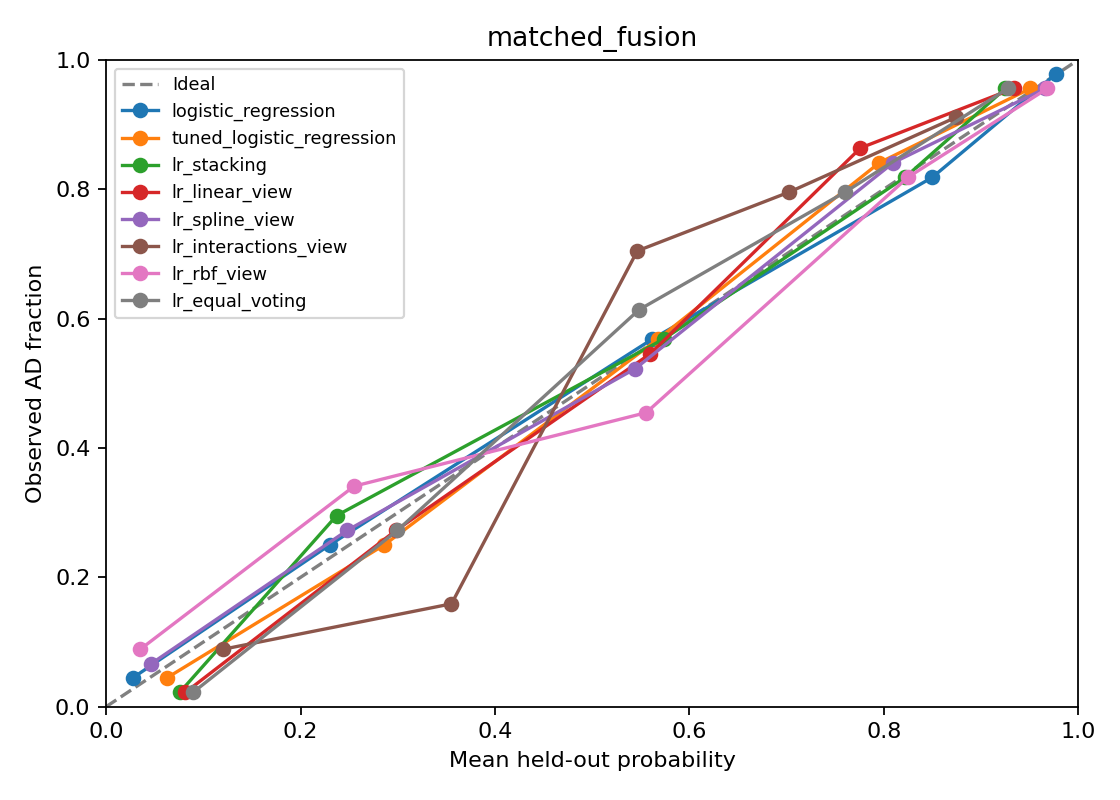

In [5]:
results = pd.read_csv(REPORT / 'metrics.csv')
columns = ['experiment', 'model', 'participants', 'accuracy', 'precision', 'sensitivity',
           'specificity', 'f1', 'balanced_accuracy', 'auroc', 'average_precision', 'brier_score']
formats = {c: '{:.1%}' for c in ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy']}
formats.update({c: '{:.3f}' for c in ['auroc', 'average_precision', 'brier_score']})
display(results[columns].style.format(formats))
display(results[['experiment', 'model', 'tn', 'fp', 'fn', 'tp']])
display(Image(filename=str(REPORT / 'calibration_matched_fusion.png')))


## 6. Did the complexity help?

The paired intervals below compare stacking and equal averaging against fixed and tuned LR on the same participants. Positive accuracy/AUROC/AP differences and negative Brier differences favor the candidate. Intervals spanning zero leave the change uncertain under this bootstrap.

The intervals condition on saved predictions, omit some retraining uncertainty, and are not adjusted for repeated comparisons.


In [6]:
display(Markdown('**Compared with fixed-C Logistic Regression**'))
display(pd.read_csv(REPORT / 'paired_vs_logistic.csv').round(4))
display(Markdown('**Compared with tuned Logistic Regression**'))
display(pd.read_csv(REPORT / 'paired_vs_tuned_logistic.csv').round(4))
display(pd.read_csv(REPORT / 'selected_parameters.csv'))
display(pd.read_csv(REPORT / 'meta_coefficients.csv').round(4))
display(Markdown((REPORT / 'results.md').read_text()))


**Compared with fixed-C Logistic Regression**

,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,lr_stacking,logistic_regression,auroc,-0.0050,-0.0129,0.0033,1000
1,clinical_reference,lr_stacking,logistic_regression,average_precision,0.0091,-0.0135,0.0325,1000
2,clinical_reference,lr_stacking,logistic_regression,brier_score,0.0040,-0.0007,0.0090,1000
3,clinical_reference,lr_stacking,logistic_regression,accuracy,-0.0068,-0.0255,0.0119,1000
4,clinical_reference,lr_equal_voting,logistic_regression,auroc,-0.0031,-0.0100,0.0049,1000
5,clinical_reference,lr_equal_voting,logistic_regression,average_precision,0.0031,-0.0164,0.0298,1000
6,clinical_reference,lr_equal_voting,logistic_regression,brier_score,0.0044,-0.0005,0.0091,1000
7,clinical_reference,lr_equal_voting,logistic_regression,accuracy,-0.0034,-0.0204,0.0136,1000
8,matched_clinical,lr_stacking,logistic_regression,auroc,-0.0158,-0.0368,0.0043,1000
9,matched_clinical,lr_stacking,logistic_regression,average_precision,-0.0257,-0.0506,-0.0025,1000


**Compared with tuned Logistic Regression**

,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,lr_stacking,tuned_logistic_regression,auroc,-0.0047,-0.0123,0.0032,1000
1,clinical_reference,lr_stacking,tuned_logistic_regression,average_precision,0.0111,-0.0131,0.0345,1000
2,clinical_reference,lr_stacking,tuned_logistic_regression,brier_score,0.0025,-0.0022,0.0077,1000
3,clinical_reference,lr_stacking,tuned_logistic_regression,accuracy,-0.0136,-0.0306,0.0051,1000
4,clinical_reference,lr_equal_voting,tuned_logistic_regression,auroc,-0.0028,-0.0103,0.0046,1000
5,clinical_reference,lr_equal_voting,tuned_logistic_regression,average_precision,0.0051,-0.0160,0.0334,1000
6,clinical_reference,lr_equal_voting,tuned_logistic_regression,brier_score,0.0029,-0.0017,0.0078,1000
7,clinical_reference,lr_equal_voting,tuned_logistic_regression,accuracy,-0.0102,-0.0255,0.0068,1000
8,matched_clinical,lr_stacking,tuned_logistic_regression,auroc,-0.0156,-0.0344,0.0023,1000
9,matched_clinical,lr_stacking,tuned_logistic_regression,average_precision,-0.0227,-0.0450,-0.0014,1000


,experiment,outer_fold,baseline_C,meta_C
0,clinical_reference,1,0.1,1.0
1,clinical_reference,2,0.1,1.0
2,clinical_reference,3,1.0,1.0
3,clinical_reference,4,0.1,0.1
4,clinical_reference,5,10.0,10.0
5,matched_clinical,1,0.1,1.0
6,matched_clinical,2,1.0,1.0
7,matched_clinical,3,0.1,0.1
8,matched_clinical,4,0.1,1.0
9,matched_clinical,5,0.1,0.1


,experiment,outer_fold,intercept,linear,spline,interactions,rbf
0,clinical_reference,1,-3.0065,2.1569,2.4280,0.5399,0.8719
1,clinical_reference,2,-2.8397,1.9945,2.1039,1.0119,0.5583
2,clinical_reference,3,-2.9477,2.5686,2.5404,0.2255,0.5752
3,clinical_reference,4,-2.2080,1.1988,1.2569,0.8682,0.8644
4,clinical_reference,5,-3.0846,3.0959,1.5656,1.3105,0.4353
5,matched_clinical,1,-2.8368,2.1035,1.5744,0.7273,1.1462
6,matched_clinical,2,-2.6266,2.1306,1.5516,0.6900,0.8685
7,matched_clinical,3,-1.2352,0.7540,0.6905,0.4819,0.6119
8,matched_clinical,4,-2.5500,1.7061,1.7877,0.1998,1.3283
9,matched_clinical,5,-1.3205,0.7843,0.7923,0.4368,0.7225


# Exploratory Logistic Regression stacking results

| Experiment | Model | N | Accuracy | AUROC | AP | Brier |
|---|---|---:|---:|---:|---:|---:|
| clinical_reference | logistic_regression | 589 | 84.4% | 0.912 | 0.852 | 0.110 |
| clinical_reference | tuned_logistic_regression | 589 | 85.1% | 0.912 | 0.850 | 0.111 |
| clinical_reference | lr_stacking | 589 | 83.7% | 0.907 | 0.861 | 0.114 |
| clinical_reference | lr_linear_view | 589 | 85.1% | 0.912 | 0.852 | 0.111 |
| clinical_reference | lr_spline_view | 589 | 83.2% | 0.912 | 0.861 | 0.113 |
| clinical_reference | lr_interactions_view | 589 | 82.2% | 0.889 | 0.817 | 0.127 |
| clinical_reference | lr_rbf_view | 589 | 82.5% | 0.880 | 0.826 | 0.133 |
| clinical_reference | lr_equal_voting | 589 | 84.0% | 0.909 | 0.855 | 0.114 |
| matched_clinical | logistic_regression | 222 | 80.6% | 0.898 | 0.917 | 0.130 |
| matched_clinical | tuned_logistic_regression | 222 | 81.1% | 0.898 | 0.914 | 0.132 |
| matched_clinical | lr_stacking | 222 | 81.5% | 0.882 | 0.892 | 0.142 |
| matched_clinical | lr_linear_view | 222 | 81.1% | 0.896 | 0.912 | 0.133 |
| matched_clinical | lr_spline_view | 222 | 81.5% | 0.886 | 0.902 | 0.136 |
| matched_clinical | lr_interactions_view | 222 | 79.3% | 0.858 | 0.870 | 0.156 |
| matched_clinical | lr_rbf_view | 222 | 81.1% | 0.870 | 0.881 | 0.146 |
| matched_clinical | lr_equal_voting | 222 | 82.0% | 0.895 | 0.909 | 0.133 |
| matched_fusion | logistic_regression | 222 | 83.8% | 0.906 | 0.919 | 0.124 |
| matched_fusion | tuned_logistic_regression | 222 | 82.0% | 0.902 | 0.913 | 0.127 |
| matched_fusion | lr_stacking | 222 | 81.1% | 0.900 | 0.909 | 0.129 |
| matched_fusion | lr_linear_view | 222 | 82.4% | 0.906 | 0.913 | 0.126 |
| matched_fusion | lr_spline_view | 222 | 83.3% | 0.888 | 0.898 | 0.133 |
| matched_fusion | lr_interactions_view | 222 | 81.1% | 0.874 | 0.881 | 0.147 |
| matched_fusion | lr_rbf_view | 222 | 76.6% | 0.866 | 0.889 | 0.150 |
| matched_fusion | lr_equal_voting | 222 | 81.5% | 0.899 | 0.906 | 0.130 |

## Interpretation

- The primary new method is lr_stacking. All four base models and the final combiner are regularized Logistic Regression.
- The base representations are linear, additive splines, pairwise numeric interactions, and approximate RBF kernel features.
- Hyperparameter search refits the entire stacking estimator inside each inner training split. Its own deeper cross-fitting trains the combiner on held-out base probabilities.
- Preprocessing is inside every base pipeline, including the deepest split. No globally precomputed transforms or outer outcomes enter training.
- Inner selection maximizes accuracy at threshold 0.5, with log loss as tie-breaker. The same selection rule is used for the tuned plain LR reference.
- Only combiner C is searched for the stack; base representation settings are prespecified. Search budgets are bounded, not equivalent in computational cost.
- Component rows and equal voting are descriptive comparisons, not separately selected winners. Meta coefficients are not causal effects or feature explanations.
- AP is non-interpolated average precision. CSV rates use the 0-1 scale; confusion entries are participant counts.
- Paired intervals compare against fixed and tuned LR, condition on predictions, omit full retraining uncertainty, and are not adjusted for multiple comparisons.
- These are exploratory comparisons using previously inspected cohorts. No external validation or guaranteed accuracy improvement is established.
- The 589-person clinical cohort differs from the matched 222-person ADNI1 cohort. Complete-case selection, provisional labels, and missing MRI/CSF comparisons remain limitations.


## What to retain

The meta coefficients describe combinations of four predicted probabilities. They are not clinical feature effects, and may be negative; they do not need to sum to one.

Share metrics.csv, paired_vs_logistic.csv, paired_vs_tuned_logistic.csv, and selected_parameters.csv. No participant-level files are needed to report aggregate performance.

Do not choose whichever component happens to score highest and call it an independently validated winner. The primary experiment is the prespecified stacking procedure. The original label, complete-case, modality, and external-validation limitations remain.

The existing hardcoded graphical comparison notebook is a snapshot of earlier results; it can be updated after this run has actual outputs.
